# 01 · Thin end-to-end pipeline — analysis (stage 4)

Loads the outputs of `python -m heisenbig.pipeline` (stages 1→3) from `data/processed/`
and plots them. **Nothing is recomputed here**; re-run the pipeline to refresh
(`bash scripts/run_thin_e2e.sh`, add `--compressor ae` for the autoencoder comparison).

> ⚠️ **Caveat — read before interpreting any number below.**
> This version uses **ENDF MF=3** cross sections. In the resolved resonance region (RRR) MF=3 holds only a
> *background*; the resonances themselves are stored as parameters in MF=2 and are **not reconstructed** here.
> For U-235 the MF=3 fission and capture curves are exactly **zero from 1e-5 eV to 2.24 keV**, and for U-238 capture up to ~20 keV, so
> thermal U-235 fission is missing entirely. **Absolute k_inf values are therefore not physically meaningful yet.**
> The point of this notebook is to show the plumbing works end to end; dense pointwise data (POINT2025 or ACE)
> will replace MF=3 later without changing the pipeline structure.

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from heisenbig.compress import PCACompressor

OUT = Path(os.environ.get("HEISENBIG_DATA", "../data")) / "processed"
run = json.loads((OUT / "run_summary.json").read_text())
grid = json.loads((OUT / "xs_wide_grid.json").read_text())
pca_err = json.loads((OUT / "pca_errors.json").read_text())
uqs = json.loads((OUT / "uq_summary.json").read_text())
E = np.array(grid["energies"])

wide = pd.read_parquet(OUT / "xs_wide")
samples = pd.read_parquet(OUT / "uq" / "samples")
models = {"pca": PCACompressor.load(OUT / "models" / "pca.joblib")}
HAS_AE = (OUT / "models" / "ae.pt").exists() and (OUT / "compressor_comparison.json").exists()
if HAS_AE:
    from heisenbig.autoencoder import AECompressor
    models["ae"] = AECompressor.load(OUT / "models" / "ae.pt")
    comp = json.loads((OUT / "compressor_comparison.json").read_text())

s1, s2, s3 = (run["stages"][k] for k in ("1_etl", "2_grid_compress", "3_uq"))
print(f"Stage 1: {s1['files']} files ({s1['failed']} failed) -> {s1['rows']:,} long rows, "
      f"{s1['curves']} curves, {s1['nuclides']} nuclides  [{s1['seconds']} s]")
print(f"Stage 2: wide matrix {s2['matrix_shape']} on {grid['n']}-pt log grid "
      f"{grid['emin']:g}-{grid['emax']:g} eV, PCA k = {s2['chosen_k']}"
      + (f", AE k = {s2['ae_chosen_k']} (Ray sweep {s2['ae_sweep_seconds']} s)" if HAS_AE else "")
      + f"  [{s2['seconds']} s]")
print(f"Stage 3: nominal k_inf original = {s3['k_inf_original']:.5f}; reconstructed: "
      + ", ".join(f"{n} {v:.5f}" for n, v in s3["k_inf_reconstructed"].items()) + f"  [{s3['seconds']} s]")
print("nu-bar source:", uqs["nu_source"])
print(f"Total pipeline wall-clock: {run['total_seconds']} s")

Stage 1: 558 files (0 failed) -> 540,577 long rows, 1758 curves, 558 nuclides  [46.8 s]
Stage 2: wide matrix [1758, 2000] on 2000-pt log grid 1e-05-2e+07 eV, PCA k = 64, AE k = 8 (Ray sweep 308.9 s)  [341.8 s]
Stage 3: nominal k_inf original = 0.66415; reconstructed: pca 0.70166, ae 0.60297  [26.6 s]
nu-bar source: {'U235': 'endf MF1/MT452', 'U238': 'endf MF1/MT452'}
Total pipeline wall-clock: 415.2 s


## 1. Cross sections on the common grid
Solid = resampled ENDF MF=3 curve; dashed = PCA reconstruction; dotted = autoencoder reconstruction (if trained). Zeros (e.g. the U-235/U-238 RRR gap) are not drawn on log axes.

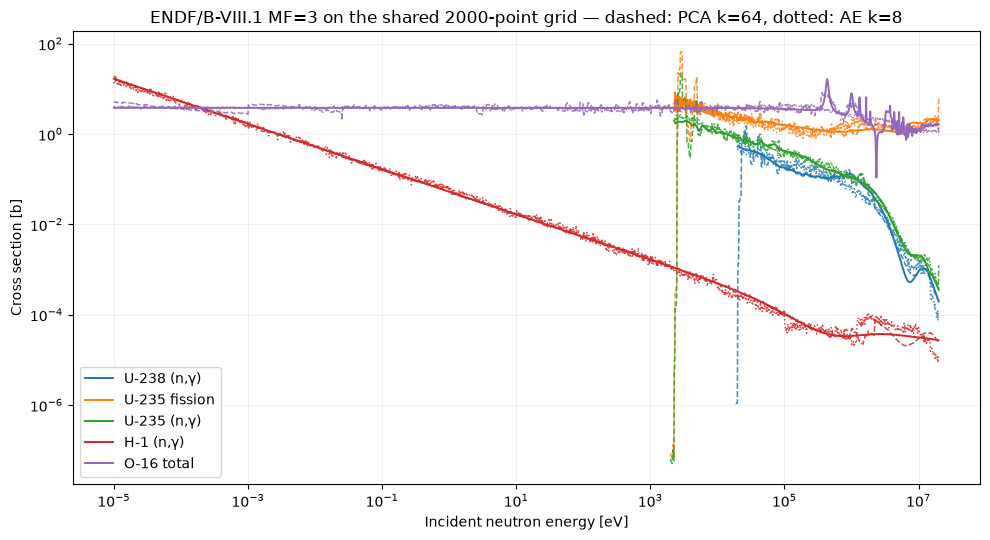

In [2]:
def row(nuc, mt):
    r = wide[(wide.nuclide == nuc) & (wide.mt == mt)]
    return np.asarray(r.iloc[0]["xs"]) if len(r) else None

picks = [("U238", 102, "U-238 (n,γ)"), ("U235", 18, "U-235 fission"), ("U235", 102, "U-235 (n,γ)"),
         ("H1", 102, "H-1 (n,γ)"), ("O16", 1, "O-16 total")]
styles = {"pca": "--", "ae": ":"}
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (nuc, mt, label) in enumerate(picks):
    x = row(nuc, mt)
    if x is None:
        continue
    c = f"C{i}"
    ax.loglog(E, np.where(x > 0, x, np.nan), color=c, lw=1.4, label=label)
    for name, m in models.items():
        rec = m.decode(m.encode(x[None]))[0]
        ax.loglog(E, np.where(rec > 1e-8, rec, np.nan), color=c, lw=1.1, ls=styles[name], alpha=.85)
title = f"ENDF/B-VIII.1 MF=3 on the shared {grid['n']}-point grid — dashed: PCA k={models['pca'].k}"
if HAS_AE:
    title += f", dotted: AE k={models['ae'].k}"
ax.set(xlabel="Incident neutron energy [eV]", ylabel="Cross section [b]", title=title)
ax.legend(); ax.grid(alpha=.3, which="both", lw=.4)
plt.tight_layout(); plt.show()

## 2. Reconstruction error vs number of components
Per-curve relative L2 error in *linear* cross-section space. Left: PCA in-sample on all curves (used to choose the PCA k). Right (with `--compressor ae`): PCA vs autoencoder on the **same held-out 20 % of curves**, both trained only on the other 80 %.

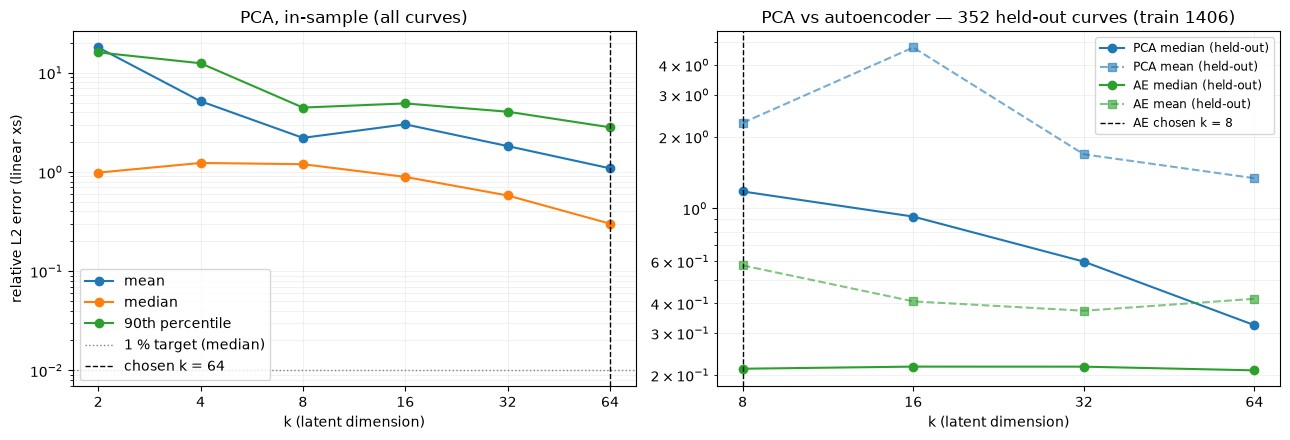

val_median_rel_err        val_mean_rel_err         \
compressor                 ae    pca               ae    pca   
k                                                              
8                       0.213  1.178            0.577  2.286   
16                      0.217  0.924            0.407  4.735   
32                      0.217  0.598            0.372  1.687   
64                      0.209  0.324            0.418  1.339   

           train_median_rel_err         
compressor                   ae    pca  
k                                       
8                         0.180  1.223  
16                        0.174  0.908  
32                        0.168  0.571  
64                        0.176  0.302

In [3]:
err = pd.DataFrame(pca_err["rows"])
fig, axes = plt.subplots(1, 2 if HAS_AE else 1, figsize=(13 if HAS_AE else 7.5, 4.5), squeeze=False)
ax = axes[0, 0]
for col, lab in [("mean_rel_err", "mean"), ("median_rel_err", "median"), ("p90_rel_err", "90th percentile")]:
    ax.semilogy(err.k, err[col], marker="o", label=lab)
ax.axhline(0.01, color="gray", ls=":", lw=1, label="1 % target (median)")
ax.axvline(pca_err["chosen_k"], color="k", ls="--", lw=1, label=f"chosen k = {pca_err['chosen_k']}")
ax.set_xscale("log", base=2); ax.set_xticks(err.k, err.k)
ax.set(xlabel="k (latent dimension)", ylabel="relative L2 error (linear xs)", title="PCA, in-sample (all curves)")
ax.legend(); ax.grid(alpha=.3, which="both", lw=.4)
if HAS_AE:
    cmp_df = pd.DataFrame(comp["rows"])
    ax = axes[0, 1]
    for name, col in (("pca", "C0"), ("ae", "C2")):
        d = cmp_df[cmp_df.compressor == name]
        ax.semilogy(d.k, d.val_median_rel_err, marker="o", color=col, label=f"{name.upper()} median (held-out)")
        ax.semilogy(d.k, d.val_mean_rel_err, marker="s", ls="--", color=col, alpha=.6, label=f"{name.upper()} mean (held-out)")
    ax.axvline(comp["ae_chosen_k"], color="k", ls="--", lw=1, label=f"AE chosen k = {comp['ae_chosen_k']}")
    ax.set_xscale("log", base=2); ax.set_xticks(sorted(cmp_df.k.unique()), sorted(cmp_df.k.unique()))
    sp = comp["split"]
    ax.set(xlabel="k (latent dimension)", title=f"PCA vs autoencoder — {sp['val']} held-out curves (train {sp['train']})")
    ax.legend(fontsize=8.5); ax.grid(alpha=.3, which="both", lw=.4)
plt.tight_layout(); plt.show()
(cmp_df.pivot(index="k", columns="compressor", values=["val_median_rel_err", "val_mean_rel_err", "train_median_rel_err"]).round(3)
 if HAS_AE else err.round(4))

## 3. Monte-Carlo k_inf: latent-space vs full grid-space sampling

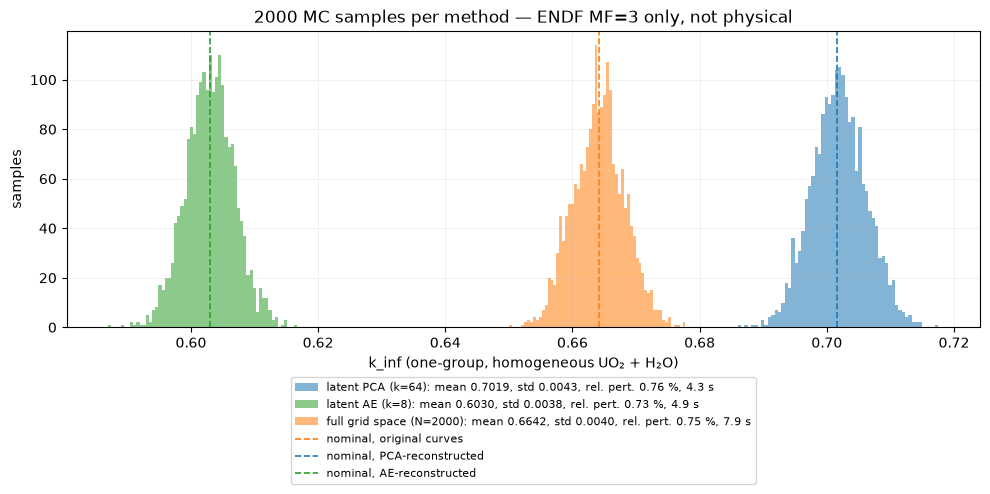

,mean,std,rel_pert_rms_mean,seconds
latent_pca,0.70188,0.00430,0.00762,4.35
latent_ae,0.60304,0.00382,0.00729,4.94
full,0.66417,0.00404,0.00745,7.90


In [4]:
mc = uqs["mc"]
methods = [m for m in ("latent_pca", "latent_ae", "full") if m in mc]
labels = {"latent_pca": f"latent PCA (k={uqs['latent']['pca']['k']})",
          "latent_ae": f"latent AE (k={uqs['latent']['ae']['k']})" if "ae" in uqs["latent"] else "",
          "full": f"full grid space (N={grid['n']})"}
colors = {"latent_pca": "C0", "latent_ae": "C2", "full": "C1"}
fig, ax = plt.subplots(figsize=(10, 5.2))
for m in methods:
    k = samples.loc[samples.method == m, "k_inf"]
    r = mc[m]
    ax.hist(k, bins=60, alpha=.55, color=colors[m],
            label=f"{labels[m]}: mean {r['mean']:.4f}, std {r['std']:.4f}, "
                  f"rel. pert. {100*r['rel_pert_rms_mean']:.2f} %, {r['seconds']:.1f} s")
ax.axvline(uqs["k_inf_nominal_original"], color=colors["full"], ls="--", lw=1.2, label="nominal, original curves")
for name, v in uqs["k_inf_nominal_reconstructed"].items():
    ax.axvline(v, color=colors[f"latent_{name}"], ls="--", lw=1.2, label=f"nominal, {name.upper()}-reconstructed")
n_per = len(samples) // len(methods)
ax.set(xlabel="k_inf (one-group, homogeneous UO₂ + H₂O)", ylabel="samples",
       title=f"{n_per} MC samples per method — ENDF MF=3 only, not physical")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1); ax.grid(alpha=.3, lw=.4)
plt.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
fig.savefig(OUT / "figures" / "thin_e2e_kinf.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({m: mc[m] for m in methods}).T.round(5)

## Reading the results
- **Plumbing:** all four stages run end to end; outputs are Parquet/JSON and reproducible (seeded MC batches, seeded AE init and training).
- **Compression:** PCA in log10 space struggles with the sharp −10 → 0 cliffs where σ is exactly zero (thresholds, the empty RRR).
  The masked autoencoder models *where* σ exists separately from *how large* it is, which targets exactly that failure mode —
  compare the held-out errors in section 2 (same split for both).
- **Propagation:** compression error shows up as a bias between each method's nominal k_inf and the original-curve value.
  Latent-space MC samples only within the compressor's manifold, so its spread is narrower than full-space MC at a
  similar per-point perturbation level; the size of that gap depends on how much of the curve variation the latent space can express.